<a href="https://colab.research.google.com/github/WahyuFairuzD/Machine-Learning/blob/main/jobsheet9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
	# Install ANNOY
	!pip install annoy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 647.5/647.5 kB 9.5 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for annoy: filename=annoy-1.17.3-cp313-cp313-linux_x86_64.whl size=520035 sha256=2768a10a9fdb267fe2e51520db9bd59d67f94f4ee7dd3f8d81e60cdf2973e60c
  Stored in directory: /root/.cache/pip/wheels/fc/4e/87/f1f957e7382aa370452cff98276f51686924d5415e449800ed
Successfully built annoy


In [ ]:
	# Import Library
	import numpy as np
	import matplotlib.pyplot as plt
	import time

	from annoy import AnnoyIndex

In [ ]:
	# Build Random Dataset and Query Point
	np.random.seed(42)
	n_points = 1000
	X = np.random.rand(n_points, 2) * 100  # random values in a 100x100 space

	# Query point (pick 1 random data point)
	query = X[np.random.randint(0, n_points)]

In [ ]:
	# Compute Exact NN Using Brute Force
	# It will visit the data one by one
	start = time.time()
	distances = np.linalg.norm(X - query, axis=1)
	idx_exact = np.argsort(distances)[:3]  # take the 3 nearest
	time_exact = time.time() - start

	print("Exact NN index:", idx_exact)
	print("Exact NN distances:", distances[idx_exact])
	print("Exact Time:", round(time_exact*1000, 4), "ms")

Exact NN index: [219 898 593]
Exact NN distances: [0.         1.36915938 2.27931544]
Exact Time: 5.0938 ms


In [ ]:
	# ANNOY 3 Trees
	f = 2  # dimensions
	t = AnnoyIndex(f, 'euclidean')
	for i, vec in enumerate(X):
	    t.add_item(i, vec)

	t.build(3)  # 3 trees

	start = time.time()
	idx_ann = t.get_nns_by_vector(query, 3)  # find 3 NN
	time_ann = time.time() - start

	print("\nAnnoy NN index:", idx_ann)
	print("Annoy NN distances:", [np.linalg.norm(X[i]-query) for i in idx_ann])
	print("Annoy Time:", round(time_ann*1000, 4), "ms")


Annoy NN index: [219, 898, 770]
Annoy NN distances: [np.float64(0.0), np.float64(1.369159376273702), np.float64(2.568167959732514)]
Annoy Time: 0.2527 ms


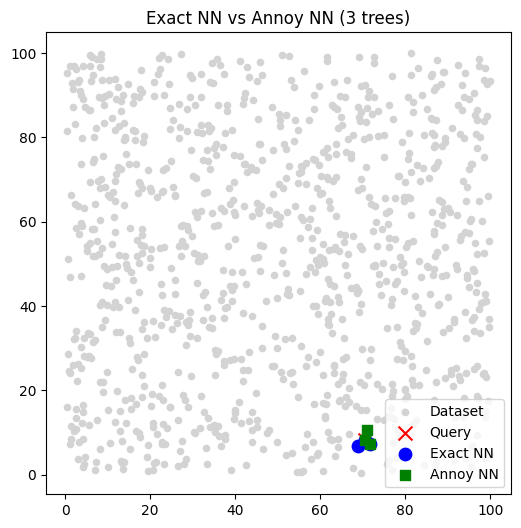

In [ ]:
	# Visualize
	# Knowing the NN produced by Exact NN and ANNOY
	plt.figure(figsize=(6,6))
	plt.scatter(X[:,0], X[:,1], c="lightgray", s=20, label="Dataset")
	plt.scatter(query[0], query[1], c="red", marker="x", s=100, label="Query")

	# Exact NN marked in blue
	plt.scatter(X[idx_exact,0], X[idx_exact,1], c="blue", s=80, label="Exact NN")

	# Annoy NN marked in green
	plt.scatter(X[idx_ann,0], X[idx_ann,1], c="green", s=50, marker="s", label="Annoy NN")

	plt.legend()
	plt.title("Exact NN vs Annoy NN (3 trees)")
	plt.show()

Lab 2

In [ ]:
	!pip install faiss-cpu
	!pip install faiss-gpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.5/19.5 MB 98.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.0/137.0 MB 52.4 MB/s  0:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 581.2/581.2 MB 15.3 MB/s  0:00:20
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.5/3.5 MB 66.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.3/68.3 MB 65.9 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.6/89.6 MB 54.5 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [faiss-gpu]


In [ ]:
	import numpy as np
	import faiss
	import matplotlib.pyplot as plt
	import time

In [ ]:
	# Build random data
	np.random.seed(42)
	X = np.random.rand(1000, 2).astype('float32')  # 1000 data points in 2D
	query = np.array([[0.5, 0.5]], dtype='float32')  # query point

In [ ]:
	# Search NN using Exact NN
	index_flat = faiss.IndexFlatL2(2)   # L2 = Euclidean distance
	index_flat.add(X)

	# Compute Exact NN Time
	start = time.time()
	D_flat, I_flat = index_flat.search(query, 3)  # Find 3 nearest neighbors
	end = time.time()
	time_flat = end - start

In [ ]:
	# Compute FAISS
	nlist = 10   # number of clusters (inverted lists)
	m = 2        # number of subvectors
	quantizer = faiss.IndexFlatL2(2)   # used by IVF for initial clustering
	index_ivfpq = faiss.IndexIVFPQ(quantizer, 2, nlist, m, 8)  # 8 bits per subvector

	index_ivfpq.train(X)  # train centroids
	index_ivfpq.add(X)

	start = time.time()
	D_ivfpq, I_ivfpq = index_ivfpq.search(query, 3)
	end = time.time()
	time_ivfpq = end - start

In [ ]:
	# Print the performances
	print("Exact NN (Flat) indices:", I_flat, "distances:", D_flat)
	print("IVF+PQ indices:", I_ivfpq, "distances:", D_ivfpq)
	print("Exact Time:", time_flat)
	print("IVF+PQ Time:", time_ivfpq)

Exact NN (Flat) indices: [[137 170 750]] distances: [[0.00013095 0.00077404 0.00079751]]
IVF+PQ indices: [[137 170 750]] distances: [[0.00012945 0.00079226 0.00080067]]
Exact Time: 0.00034046173095703125
IVF+PQ Time: 0.00025653839111328125


In [ ]:
	# Visualize
	plt.scatter(X[:,0], X[:,1], alpha=0.4, label="Dataset")
	plt.scatter(query[:,0], query[:,1], c='red', marker='*', s=200, label="Query")

	# Flat NN -> Exact NN
	plt.scatter(X[I_flat[0],0], X[I_flat[0],1], c='blue', s=100, edgecolor='k', label="Exact NN")

	# IVF+PQ NN -> FAISS
	plt.scatter(X[I_ivfpq[0],0], X[I_ivfpq[0],1], c='green', marker='x', s=100, label="IVF+PQ NN")

	plt.legend()
	plt.title("Exact NN vs FAISS IVF+PQ")
	plt.show()

Lab 3

In [ ]:
!pip install hnswlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for hnswlib: filename=hnswlib-0.8.0-cp313-cp313-linux_x86_64.whl size=2679797 sha256=ff70eaff030883b04fadd01afb8deba5577043c86edab21bc3065ea96a4d103b
  Stored in directory: /root/.cache/pip/wheels/35/04/88/b31765a4b9957705e18065db4657e61fc8da54f50e3ef0b67e
Successfully built hnswlib


In [ ]:
	import hnswlib
	import numpy as np
	import time
	from sklearn.neighbors import NearestNeighbors

In [ ]:
	# Build Dummy Dataset
	num_elements = 1000
	dim = 2
	data = np.random.random((num_elements, dim)).astype(np.float32)

	# Query point
	query = np.array([[0.5, 0.5]], dtype=np.float32)
	k = 5  # search for 5 nearest neighbors

In [ ]:
# Build NN Model
nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
nn.fit(data)

# Compute time performance
start = time.time()
distances, indices = nn.kneighbors(query)
end = time.time()

print("=== Exact NN ===")
print("Indices:", indices)
print("Distances:", distances)
print("Time:", end - start, "s")

=== Exact NN ===
Indices: [[830 247 473 913 592]]
Distances: [[0.00993625 0.01363944 0.01646171 0.03779694 0.03859071]]
Time: 0.1212460994720459 s


In [ ]:
	# Initiate Index
	p = hnswlib.Index(space='l2', dim=dim)

	# Define Max Elements
	p.init_index(max_elements=num_elements, ef_construction=100, M=16)

	# Add Data
	p.add_items(data)

	# Set searching parameter
	p.set_ef(50)   # tradeoff speed vs accuracy

	start = time.time()
	labels, distances = p.knn_query(query, k=k)
	end = time.time()

	print("\n=== HNSW ===")
	print("Indices:", labels)
	print("Distances:", distances)
	print("Time:", end - start, "s")


=== HNSW ===
Indices: [[830 247 473 913 592]]
Distances: [[9.8728990e-05 1.8603441e-04 2.7098786e-04 1.4286089e-03 1.4892431e-03]]
Time: 0.00029206275939941406 s


Lab 4

In [ ]:
	import numpy as np
	import time
	from annoy import AnnoyIndex
	import faiss
	import hnswlib

	# ===============================
	# Build 1 million rows with 5 dimensions
	# ===============================
	n_data = 1_000_000   # use 100_000 if memory is constrained
	dim = 5
	X = np.random.random((n_data, dim)).astype(np.float32)

	# Query point
	query = np.random.random((1, dim)).astype(np.float32)
	k = 10

	# ===============================
	# 2. Annoy
	# ===============================
	print("=== Annoy ===")
	ann_index = AnnoyIndex(dim, 'euclidean')

	start = time.time()
	for i in range(n_data):
	    ann_index.add_item(i, X[i])
	ann_index.build(10)  # 10 trees
	build_time = time.time() - start

	start = time.time()
	neighbors = ann_index.get_nns_by_vector(query[0], k, include_distances=True)
	query_time = time.time() - start

	print("Build time:", build_time, "seconds")
	print("Query time:", query_time, "seconds")
	print("Neighbors:", neighbors[0][:5], "...")

	# ===============================
	# 3. FAISS (Flat Index)
	# ===============================
	print("\n=== FAISS (IndexFlatL2) ===")
	faiss_index = faiss.IndexFlatL2(dim)

	start = time.time()
	faiss_index.add(X)
	build_time = time.time() - start

	start = time.time()
	distances, indices = faiss_index.search(query, k)
	query_time = time.time() - start

	print("Build time:", build_time, "seconds")
	print("Query time:", query_time, "seconds")
	print("Neighbors:", indices[0][:5], "...")

	# ===============================
	# 4. HNSW (hnswlib)
	# ===============================
	print("\n=== HNSW (hnswlib) ===")
	hnsw_index = hnswlib.Index(space='l2', dim=dim)

	start = time.time()
	hnsw_index.init_index(max_elements=n_data, ef_construction=200, M=16)
	hnsw_index.add_items(X)
	build_time = time.time() - start

	hnsw_index.set_ef(50)

	start = time.time()
	labels, distances = hnsw_index.knn_query(query, k=k)
	query_time = time.time() - start

	print("Build time:", build_time, "seconds")
	print("Query time:", query_time, "seconds")
	print("Neighbors:", labels[0][:5], "...")

=== Annoy ===
Build time: 27.580003023147583 seconds
Query time: 0.005031585693359375 seconds
Neighbors: [129179, 559276, 630783, 213191, 559393] ...

=== FAISS (IndexFlatL2) ===
Build time: 0.07713484764099121 seconds
Query time: 0.036333322525024414 seconds
Neighbors: [129179 559276 630783 213191 559393] ...

=== HNSW (hnswlib) ===
Build time: 200.2708752155304 seconds
Query time: 0.00083160400390625 seconds
Neighbors: [129179 559276 630783 213191 559393] ...


Lab 5


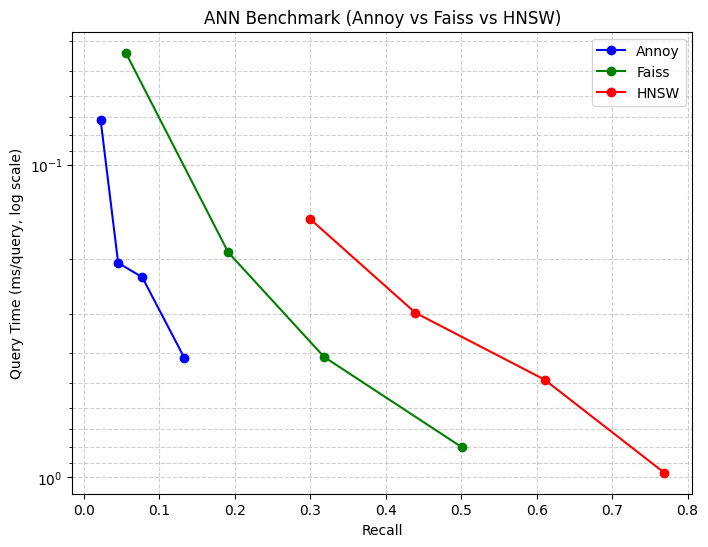

In [ ]:
	import numpy as np
	import time
	import faiss
	from annoy import AnnoyIndex
	import hnswlib
	import matplotlib.pyplot as plt

	# -------------------------------
	# Random dataset
	# -------------------------------
	d = 128        # dimension
	nb = 100000    # number of database vectors
	nq = 1000      # number of queries

	np.random.seed(42)
	xb = np.random.random((nb, d)).astype('float32')
	xq = np.random.random((nq, d)).astype('float32')

	# -------------------------------
	# Ground truth with FAISS brute force
	# -------------------------------
	index_flat = faiss.IndexFlatL2(d)
	index_flat.add(xb)
	k = 10
	_, gt_idx = index_flat.search(xq, k)

	# -------------------------------
	# Recall function
	# -------------------------------
	def recall_at_k(I_pred, I_gt, k):
	    correct = 0
	    for i in range(len(I_pred)):
	        correct += len(set(I_pred[i][:k]) & set(I_gt[i][:k]))
	    return correct / (len(I_pred) * k)

	# -------------------------------
	# Annoy benchmark
	# -------------------------------
	def run_annoy(xb, xq, n_trees=10, search_k=1000, k=10):
	    f = xb.shape[1]
	    index = AnnoyIndex(f, 'euclidean')
	    for i, v in enumerate(xb):
	        index.add_item(i, v)
	    index.build(n_trees)

	    start = time.time()
	    I = [index.get_nns_by_vector(v, k, search_k=search_k) for v in xq]
	    elapsed = (time.time() - start) * 1000 / len(xq)  # ms/query
	    rec = recall_at_k(I, gt_idx, k)
	    return rec, elapsed

	# -------------------------------
	# FAISS IVF benchmark
	# -------------------------------
	def run_faiss(xb, xq, nlist=100, nprobe=10, k=10):
	    quantizer = faiss.IndexFlatL2(d)
	    index = faiss.IndexIVFFlat(quantizer, d, nlist, faiss.METRIC_L2)
	    index.train(xb)
	    index.add(xb)

	    index.nprobe = nprobe
	    start = time.time()
	    _, I = index.search(xq, k)
	    elapsed = (time.time() - start) * 1000 / len(xq)
	    rec = recall_at_k(I, gt_idx, k)
	    return rec, elapsed

	# -------------------------------
	# HNSW benchmark
	# -------------------------------
	def run_hnsw(xb, xq, ef=100, M=16, k=10):
	    num_elements = xb.shape[0]
	    p = hnswlib.Index(space='l2', dim=d)
	    p.init_index(max_elements=num_elements, ef_construction=200, M=M)
	    p.add_items(xb)
	    p.set_ef(ef)

	    start = time.time()
	    I, _ = p.knn_query(xq, k)
	    elapsed = (time.time() - start) * 1000 / len(xq)
	    rec = recall_at_k(I, gt_idx, k)
	    return rec, elapsed

	# -------------------------------
	# Run benchmark with several parameters
	# -------------------------------
	results = {"Annoy": [], "Faiss": [], "HNSW": []}

	# Annoy
	for sk in [200, 500, 1000, 2000]:
	    rec, t = run_annoy(xb, xq, n_trees=10, search_k=sk)
	    results["Annoy"].append((rec, t))

	# FAISS
	for npb in [1, 5, 10, 20]:
	    rec, t = run_faiss(xb, xq, nlist=100, nprobe=npb)
	    results["Faiss"].append((rec, t))

	# HNSW
	for ef in [50, 100, 200, 400]:
	    rec, t = run_hnsw(xb, xq, ef=ef)
	    results["HNSW"].append((rec, t))

	# -------------------------------
	# Visualize the trade-off
	# -------------------------------
	plt.figure(figsize=(8,6))
	for label, color in zip(results.keys(), ["blue","green","red"]):
	    recall, qtime = zip(*results[label])
	    plt.plot(recall, qtime, marker="o", label=label, color=color)

	plt.xlabel("Recall")
	plt.ylabel("Query Time (ms/query, log scale)")
	plt.yscale("log")
	plt.gca().invert_yaxis()  # invert Y, the more to the right the lower
	plt.title("ANN Benchmark (Annoy vs Faiss vs HNSW)")
	plt.legend()
	plt.grid(True, which="both", ls="--", alpha=0.6)
	plt.show()

Assignment 1

In [ ]:
!pip install annoy faiss-cpu hnswlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.5/19.5 MB 26.5 MB/s  0:00:00
  Created wheel for hnswlib: filename=hnswlib-0.8.0-cp313-cp313-linux_x86_64.whl size=2679799 sha256=8f37e3a13834d022e9c22d44fa1281d192496d2b06fe22b0d2bd7c73041489ab
  Stored in directory: /root/.cache/pip/wheels/35/04/88/b31765a4b9957705e18065db4657e61fc8da54f50e3ef0b67e
Successfully built hnswlib
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [faiss-cpu]


In [ ]:
import numpy as np
import pandas as pd
import time

from annoy import AnnoyIndex
import faiss
import hnswlib

In [ ]:
# Assignment 1 - Benchmark FAISS (IVF-Flat)

def benchmark_faiss(X, queries, metric, ground_truth):
    dim = X.shape[1]

    nlist = min(100, max(1, int(np.sqrt(len(X)))))
    nprobe = min(10, nlist)

    if metric == "Euclidean":
        quantizer = faiss.IndexFlatL2(dim)
        faiss_metric = faiss.METRIC_L2
    else:
        quantizer = faiss.IndexFlatIP(dim)
        faiss_metric = faiss.METRIC_INNER_PRODUCT

    index = faiss.IndexIVFFlat(
        quantizer,
        dim,
        nlist,
        faiss_metric
    )

    # Mengukur waktu pembangunan index
    start = time.perf_counter()

    index.train(X)
    index.add(X)

    build_seconds = time.perf_counter() - start

    index.nprobe = nprobe

    # Melakukan pencarian
    def search_one(q):
        _, ids = index.search(
            q.reshape(1, -1),
            K
        )
        return ids[0].tolist()

    predicted, query_ms = average_query_time_ms(
        search_one,
        queries
    )

    recall = recall_at_k(predicted, ground_truth)

    return {
        "Algorithm": "FAISS (IVF-Flat)",
        "Build Time (s)": build_seconds,
        "Query Time (ms/query)": query_ms,
        "Recall@10": recall
    }

In [ ]:
 # benchmark HNSW

def benchmark_hnsw(
    X, queries, metric, ground_truth,
    M=16, ef_construction=100, ef_search=50
):
    dim = X.shape[1]

    space = "l2" if metric == "Euclidean" else "cosine"

    index = hnswlib.Index(space=space, dim=dim)

    # Mengukur waktu pembangunan index
    start = time.perf_counter()

    index.init_index(
        max_elements=len(X),
        ef_construction=ef_construction,
        M=M
    )

    index.add_items(X)

    build_seconds = time.perf_counter() - start

    index.set_ef(max(ef_search, K))

    # Melakukan pencarian
    def search_one(q):
        labels, distances = index.knn_query(
            q.reshape(1, -1),
            k=K
        )
        return labels[0].tolist()

    predicted, query_ms = average_query_time_ms(
        search_one,
        queries
    )

    recall = recall_at_k(predicted, ground_truth)

    return {
        "Algorithm": "HNSW",
        "Build Time (s)": build_seconds,
        "Query Time (ms/query)": query_ms,
        "Recall@10": recall
    }

In [ ]:
# Assignment 1 - Benchmark ANNOY

def benchmark_annoy(X, queries, metric, ground_truth, n_trees=10, search_k=-1):

    dim = X.shape[1]

    annoy_metric = "euclidean" if metric == "Euclidean" else "angular"

    index = AnnoyIndex(dim, annoy_metric)

    # Build index
    start = time.perf_counter()

    for i, vector in enumerate(X):
        index.add_item(i, vector)

    index.build(n_trees)

    build_seconds = time.perf_counter() - start

    # Search
    predicted, query_ms = average_query_time_ms(
        lambda q: index.get_nns_by_vector(
            q.tolist(), K, search_k=search_k
        ),
        queries
    )

    # Recall
    recall = recall_at_k(predicted, ground_truth)

    return {
        "Algorithm": "ANNOY",
        "Build Time (s)": build_seconds,
        "Query Time (ms/query)": query_ms,
        "Recall@10": recall
    }

In [ ]:
# Assignment 1 - Run All Experiments

experiment_settings = [
    (1_000, 2, "Euclidean"),
    (1_000, 2, "Cosine"),
    (1_000_000, 5, "Euclidean"),
    (1_000_000, 5, "Cosine"),
]

assignment_results = []

for n_data, dim, metric in experiment_settings:

    print("\n" + "=" * 65)
    print(f"Dataset: {n_data:,} | Dimension: {dim}D | Metric: {metric}")
    print("=" * 65)

    # Membuat dataset dan query
    X, queries = generate_dataset(n_data, dim)

    # Persiapan metric
    X_metric, queries_metric = prepare_metric_data(
        X, queries, metric
    )

    # Exact Ground Truth
    ground_truth = exact_ground_truth(
        X_metric, queries_metric, metric, K
    )

    # Benchmark ANNOY
    result_annoy = benchmark_annoy(
        X_metric, queries_metric, metric, ground_truth,
        n_trees=10, search_k=-1
    )

    # Benchmark FAISS
    result_faiss = benchmark_faiss(
        X_metric, queries_metric, metric, ground_truth
    )

    # Benchmark HNSW
    result_hnsw = benchmark_hnsw(
        X_metric, queries_metric, metric, ground_truth,
        M=16, ef_construction=100, ef_search=50
    )

    # Menyimpan hasil
    for result in [result_annoy, result_faiss, result_hnsw]:

        result["Number of Data"] = n_data
        result["Dimensions"] = f"{dim}D"
        result["Metric"] = metric

        assignment_results.append(result)

    # Menampilkan hasil per dataset
    display(
        pd.DataFrame(
            [result_annoy, result_faiss, result_hnsw]
        ).round(4)
    )

print("\nSEMUA EKSPERIMEN SELESAI!")


Dataset: 1,000 | Dimension: 2D | Metric: Euclidean


,Algorithm,Build Time (s),Query Time (ms/query),Recall@10,Number of Data,Dimensions,Metric
0,ANNOY,0.0241,0.0370,0.998,1000,2D,Euclidean
1,FAISS (IVF-Flat),0.0045,0.0237,1.000,1000,2D,Euclidean
2,HNSW,0.0304,0.0210,1.000,1000,2D,Euclidean



Dataset: 1,000 | Dimension: 2D | Metric: Cosine


,Algorithm,Build Time (s),Query Time (ms/query),Recall@10,Number of Data,Dimensions,Metric
0,ANNOY,0.0350,0.0251,0.993,1000,2D,Cosine
1,FAISS (IVF-Flat),0.0036,0.0235,1.000,1000,2D,Cosine
2,HNSW,0.0276,0.0185,1.000,1000,2D,Cosine



Dataset: 1,000,000 | Dimension: 5D | Metric: Euclidean


,Algorithm,Build Time (s),Query Time (ms/query),Recall@10,Number of Data,Dimensions,Metric
0,ANNOY,19.1338,0.0581,0.936,1000000,5D,Euclidean
1,FAISS (IVF-Flat),0.1909,1.0127,1.000,1000000,5D,Euclidean
2,HNSW,84.3567,0.0530,1.000,1000000,5D,Euclidean



Dataset: 1,000,000 | Dimension: 5D | Metric: Cosine


,Algorithm,Build Time (s),Query Time (ms/query),Recall@10,Number of Data,Dimensions,Metric
0,ANNOY,27.7967,0.0583,0.972,1000000,5D,Cosine
1,FAISS (IVF-Flat),0.3279,1.2579,0.999,1000000,5D,Cosine
2,HNSW,78.7630,0.0493,1.000,1000000,5D,Cosine



SEMUA EKSPERIMEN SELESAI!


Assignment 2


In [ ]:
import pandas as pd
import numpy as np
import time
import faiss

from annoy import AnnoyIndex
import hnswlib

from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("bwandowando/spotify-songs-with-attributes-and-lyrics")

print("Path to dataset files:", path)

100%|██████████| 894M/894M [00:11<00:00, 81.0MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/bwandowando/spotify-songs-with-attributes-and-lyrics/versions/20


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving spotify_audio_features.csv to spotify_audio_features.csv


In [ ]:
df = pd.read_csv('spotify_audio_features.csv')

features = ['danceability', 'energy', 'loudness', 'speechiness',
            'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']

X = df[features].values

# Feature standardization
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

k = 10  # number of nearest neighbors

In [ ]:
print("Dataset shape:", df.shape)
print("\nFeature shape:", X_scaled.shape)
print("\nMissing values:")
print(df.isnull().sum())

display(df.head())

Dataset shape: (955320, 9)

Feature shape: (955320, 9)

Missing values:
danceability        0
energy              0
loudness            0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
dtype: int64


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,0.415,0.6050,-11.157,0.0575,0.00116,0.838000,0.4710,0.193,100.059
1,0.788,0.6480,-9.135,0.3150,0.90000,0.000000,0.1760,0.287,79.998
2,0.000,0.0354,-20.151,0.0000,0.90800,0.000000,0.4790,0.000,0.000
3,0.657,0.8820,-6.340,0.0385,0.00740,0.000013,0.0474,0.939,123.588
4,0.659,0.8930,-8.531,0.0411,0.09220,0.000019,0.0534,0.951,123.600


In [ ]:
# Exact Nearest Neighbor Benchmark

# Menggunakan 100 query untuk benchmark
np.random.seed(42)

query_indices = np.random.choice(len(X_scaled), 100, replace=False)
queries = X_scaled[query_indices]

# Membuat Exact NN model
exact_nn = NearestNeighbors(
    n_neighbors=k,
    algorithm='brute',
    metric='euclidean'
)

# Mengukur build time
start = time.time()
exact_nn.fit(X_scaled)
build_time_exact = time.time() - start

# Mengukur query time
start = time.time()
exact_distances, exact_indices = exact_nn.kneighbors(queries)
query_time_exact = (time.time() - start) / len(queries) * 1000

print("Exact NN Build Time:", round(build_time_exact, 4), "seconds")
print("Exact NN Query Time:", round(query_time_exact, 4), "ms/query")
print("Exact NN Results Shape:", exact_indices.shape)

Exact NN Build Time: 0.1019 seconds
Exact NN Query Time: 25.4067 ms/query
Exact NN Results Shape: (100, 10)


In [ ]:
# ANNOY Benchmark

dim = X_scaled.shape[1]

annoy_index = AnnoyIndex(dim, 'euclidean')

# Build index
start = time.time()

for i, vector in enumerate(X_scaled):
    annoy_index.add_item(i, vector)

annoy_index.build(10)

build_time_annoy = time.time() - start

# Search nearest neighbors
start = time.time()

annoy_indices = []

for q in queries:
    neighbors = annoy_index.get_nns_by_vector(
        q.tolist(),
        k
    )
    annoy_indices.append(neighbors)

query_time_annoy = (time.time() - start) / len(queries) * 1000

# Recall@10
recall_annoy = np.mean([
    len(set(annoy_indices[i]) & set(exact_indices[i])) / k
    for i in range(len(queries))
])

print("ANNOY Build Time:", round(build_time_annoy, 4), "seconds")
print("ANNOY Query Time:", round(query_time_annoy, 4), "ms/query")
print("ANNOY Recall@10:", round(recall_annoy, 4))

ANNOY Build Time: 20.992 seconds
ANNOY Query Time: 0.0623 ms/query
ANNOY Recall@10: 0.833


In [ ]:
# FAISS Benchmark (IVF-Flat)

dim = X_scaled.shape[1]

nlist = 100  # number of clusters
nprobe = 10  # clusters searched

quantizer = faiss.IndexFlatL2(dim)

faiss_index = faiss.IndexIVFFlat(
    quantizer,
    dim,
    nlist,
    faiss.METRIC_L2
)

# Build index
start = time.time()

faiss_index.train(X_scaled)
faiss_index.add(X_scaled)

build_time_faiss = time.time() - start

faiss_index.nprobe = nprobe

# Search nearest neighbors
start = time.time()

faiss_distances, faiss_indices = faiss_index.search(queries, k)

query_time_faiss = (time.time() - start) / len(queries) * 1000

# Recall@10
recall_faiss = np.mean([
    len(set(faiss_indices[i]) & set(exact_indices[i])) / k
    for i in range(len(queries))
])

print("FAISS Build Time:", round(build_time_faiss, 4), "seconds")
print("FAISS Query Time:", round(query_time_faiss, 4), "ms/query")
print("FAISS Recall@10:", round(recall_faiss, 4))

FAISS Build Time: 0.9847 seconds
FAISS Query Time: 3.6633 ms/query
FAISS Recall@10: 0.999


In [ ]:
# HNSW Benchmark

dim = X_scaled.shape[1]

hnsw_index = hnswlib.Index(
    space='l2',
    dim=dim
)

# Build index
start = time.time()

hnsw_index.init_index(
    max_elements=len(X_scaled),
    ef_construction=100,
    M=16
)

hnsw_index.add_items(X_scaled)

build_time_hnsw = time.time() - start

hnsw_index.set_ef(50)

# Search nearest neighbors
start = time.time()

hnsw_indices, hnsw_distances = hnsw_index.knn_query(
    queries,
    k=k
)

query_time_hnsw = (time.time() - start) / len(queries) * 1000

# Recall@10
recall_hnsw = np.mean([
    len(set(hnsw_indices[i]) & set(exact_indices[i])) / k
    for i in range(len(queries))
])

print("HNSW Build Time:", round(build_time_hnsw, 4), "seconds")
print("HNSW Query Time:", round(query_time_hnsw, 4), "ms/query")
print("HNSW Recall@10:", round(recall_hnsw, 4))

HNSW Build Time: 104.2946 seconds
HNSW Query Time: 0.0518 ms/query
HNSW Recall@10: 0.993


In [ ]:
# Final Comparison Table

results = {
    "Algorithm": ["Exact NN", "ANNOY", "FAISS (IVF-Flat)", "HNSW"],
    "Build Time (s)": [
        build_time_exact,
        build_time_annoy,
        build_time_faiss,
        build_time_hnsw
    ],
    "Query Time (ms/query)": [
        query_time_exact,
        query_time_annoy,
        query_time_faiss,
        query_time_hnsw
    ],
    "Recall@10": [
        1.000,
        recall_annoy,
        recall_faiss,
        recall_hnsw
    ]
}

comparison_df = pd.DataFrame(results)

display(comparison_df.round(4))

,Algorithm,Build Time (s),Query Time (ms/query),Recall@10
0,Exact NN,0.1019,25.4067,1.000
1,ANNOY,20.9920,0.0623,0.833
2,FAISS (IVF-Flat),0.9847,3.6633,0.999
3,HNSW,104.2946,0.0518,0.993
